# 🏏 IPL Data Analysis (2008–2024)

An end-to-end exploratory analysis of the Indian Premier League using the real public IPL dataset: **matches.csv** (one row per match) and **deliveries.csv** (one row per ball). Every number in this notebook is computed from those two files — nothing is copied from articles or scorecards.

**Data cleaning applied up front:** season labels normalised (`2007/08` → `2008`, `2009/10` → `2010`, `2020/21` → `2020`) and renamed franchises merged (Delhi Daredevils → Delhi Capitals, Kings XI Punjab → Punjab Kings, Royal Challengers Bangalore → Royal Challengers Bengaluru, Rising Pune Supergiant → Rising Pune Supergiants).

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

# Normalise season labels ('2007/08' -> '2008', '2020/21' -> '2020') so the
# season column sorts and groups like a year.
SEASON_FIX = {"2007/08": "2008", "2009/10": "2010", "2020/21": "2020"}
matches["season"] = matches["season"].astype(str).replace(SEASON_FIX)

# Canonical team names (franchise renames merged)
TEAM_FIX = {
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiant": "Rising Pune Supergiants",
}
for col in ("team1", "team2", "winner", "toss_winner"):
    matches[col] = matches[col].replace(TEAM_FIX)
for col in ("batting_team", "bowling_team"):
    deliveries[col] = deliveries[col].replace(TEAM_FIX)

decided = matches[matches["winner"].notna()].copy()
print("matches rows:", len(matches), "| deliveries rows:", len(deliveries))
matches.head()

matches rows: 1095 | deliveries rows: 260920


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2008,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bengaluru,Kolkata Knight Riders,Royal Challengers Bengaluru,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2008,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Punjab Kings,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2008,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Capitals,Rajasthan Royals,Rajasthan Royals,bat,Delhi Capitals,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2008,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bengaluru,Mumbai Indians,bat,Royal Challengers Bengaluru,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2008,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


## 2. Matches per season

How big is each season? The league grew from 8 teams to 10 in 2022, which shows up directly in the match counts.

season
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
2024    71


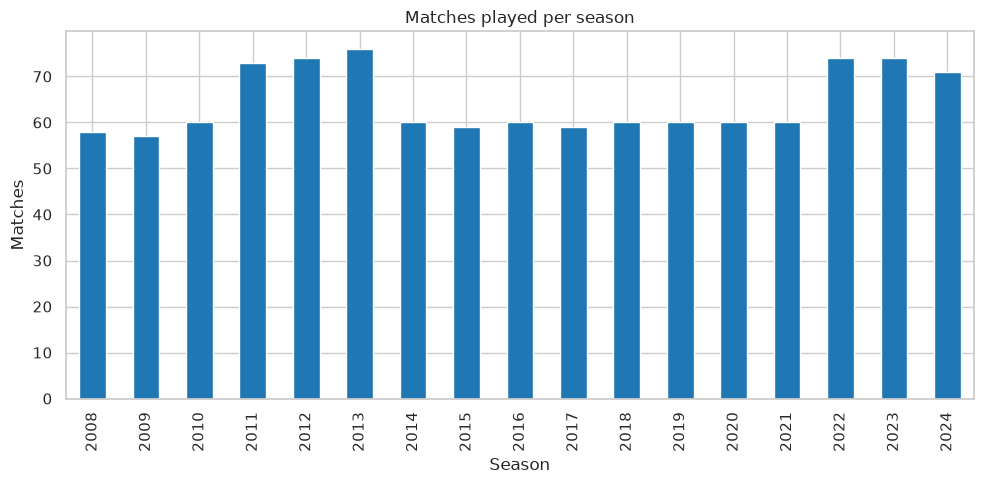

In [2]:
matches_per_season = matches.groupby("season", sort=True).size()
print(matches_per_season.to_string())

ax = matches_per_season.plot(kind="bar", color="#1f77b4")
ax.set_xlabel("Season"); ax.set_ylabel("Matches")
ax.set_title("Matches played per season")
plt.tight_layout(); plt.show()

## 3. Most successful teams

Total wins, plus matches played and win percentage so short-lived teams can be compared fairly with the ever-present ones.

                             played  wins  win_pct
Mumbai Indians                  261   144     55.2
Chennai Super Kings             238   138     58.0
Kolkata Knight Riders           251   131     52.2
Royal Challengers Bengaluru     255   123     48.2
Delhi Capitals                  252   115     45.6
Punjab Kings                    246   112     45.5
Rajasthan Royals                221   112     50.7
Sunrisers Hyderabad             182    88     48.4
Deccan Chargers                  75    29     38.7
Gujarat Titans                   45    28     62.2
Lucknow Super Giants             44    24     54.5
Rising Pune Supergiants          30    15     50.0
Gujarat Lions                    30    13     43.3
Pune Warriors                    46    12     26.1
Kochi Tuskers Kerala             14     6     42.9


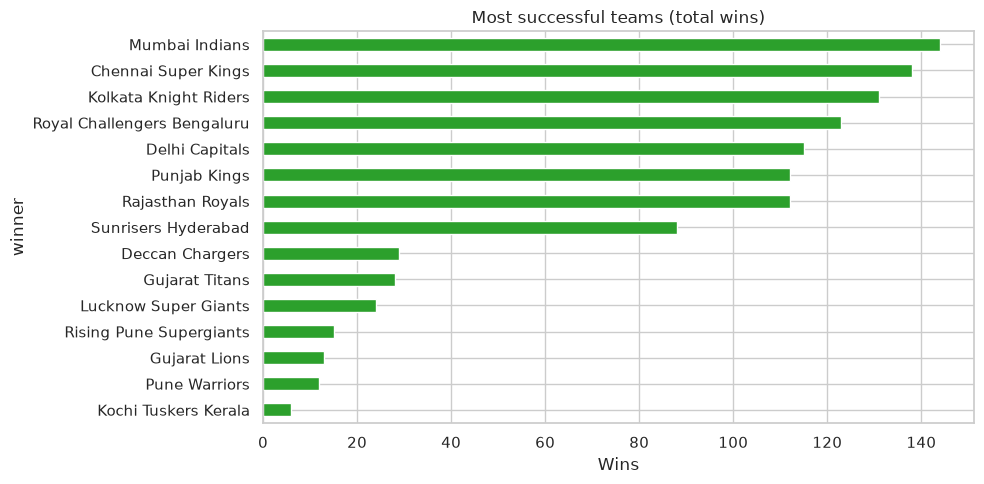

In [3]:
wins = decided["winner"].value_counts()
played = pd.concat([matches["team1"], matches["team2"]]).value_counts()
team_table = pd.DataFrame({"played": played, "wins": wins}).fillna(0)
team_table["win_pct"] = (100 * team_table["wins"] / team_table["played"]).round(1)
team_table = team_table.sort_values("wins", ascending=False)
print(team_table.to_string())

ax = wins.sort_values().plot(kind="barh", color="#2ca02c")
ax.set_xlabel("Wins"); ax.set_title("Most successful teams (total wins)")
plt.tight_layout(); plt.show()

## 4. The toss — does it matter?

Captains overwhelmingly choose to field first. The real question: how often does winning the toss actually turn into winning the match, and does the decision (bat vs field) change that?

Toss decisions (% of all matches):
toss_decision
field    64.3
bat      35.7

Toss winner also won the match in 50.8% of decided matches

By decision:
toss_decision
bat      45.4
field    53.9


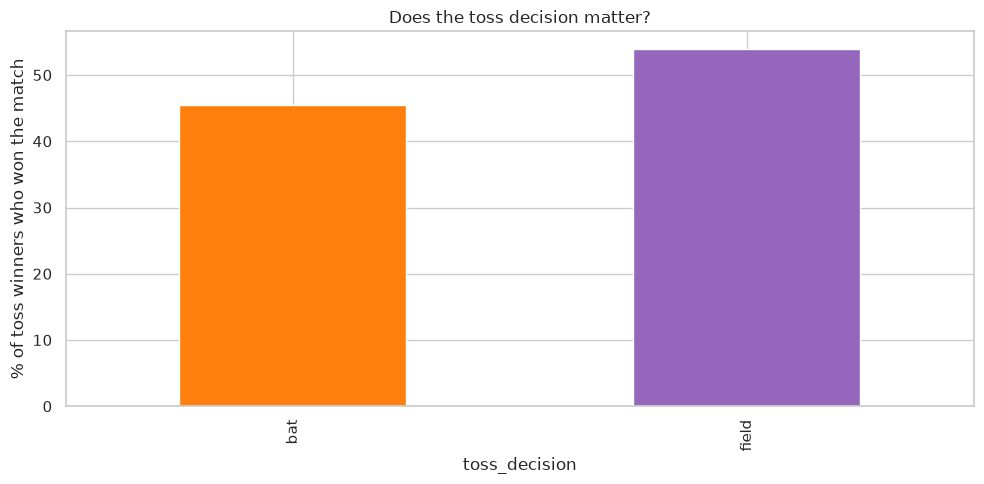

In [4]:
toss_counts = matches["toss_decision"].value_counts(normalize=True).mul(100).round(1)
decided_toss = decided.copy()
decided_toss["toss_won_match"] = decided_toss["toss_winner"] == decided_toss["winner"]
toss_win_pct = decided_toss["toss_won_match"].mean() * 100
by_decision = decided_toss.groupby("toss_decision")["toss_won_match"].mean().mul(100).round(1)
print("Toss decisions (% of all matches):"); print(toss_counts.to_string())
print(f"\nToss winner also won the match in {toss_win_pct:.1f}% of decided matches")
print("\nBy decision:"); print(by_decision.to_string())

ax = by_decision.plot(kind="bar", color=["#ff7f0e", "#9467bd"])
ax.set_ylabel("% of toss winners who won the match")
ax.set_title("Does the toss decision matter?")
plt.tight_layout(); plt.show()

## 5. Player of the Match awards

The most decorated individual performers.

player_of_match
AB de Villiers    25
CH Gayle          22
RG Sharma         19
DA Warner         18
V Kohli           18
MS Dhoni          17
SR Watson         16
YK Pathan         16
RA Jadeja         16
SP Narine         15


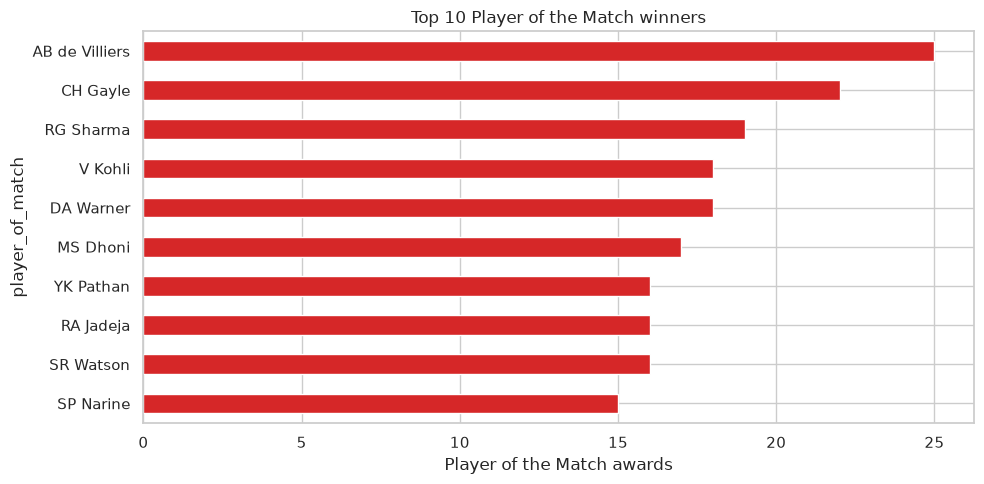

In [5]:
pom = matches["player_of_match"].value_counts().head(10)
print(pom.to_string())

ax = pom.sort_values().plot(kind="barh", color="#d62728")
ax.set_xlabel("Player of the Match awards"); ax.set_title("Top 10 Player of the Match winners")
plt.tight_layout(); plt.show()

## 6. Venues

Which grounds host the most cricket, and where do teams score the most batting first? First-innings totals come from deliveries.csv (innings 1 only, super overs excluded).

In [6]:
venue_counts = matches["venue"].value_counts().head(10)
print("Most-used venues:"); print(venue_counts.to_string())

d12 = deliveries[deliveries["inning"].isin([1, 2])]
first_innings = d12[d12["inning"] == 1].groupby("match_id")["total_runs"].sum()
print(f"\nAverage first-innings score: {first_innings.mean():.1f} "
      f"(median {first_innings.median():.0f}, based on {len(first_innings)} innings)")

venue_of = matches.set_index("id")["venue"]
fi = first_innings.rename("score").reset_index().rename(columns={"match_id": "id"})
fi["venue"] = fi["id"].map(venue_of)
venue_avg = fi.groupby("venue")["score"].agg(["mean", "count"])
venue_avg = venue_avg[venue_avg["count"] >= 20].sort_values("mean", ascending=False)
print("\nAverage 1st-innings score by venue (min 20 matches):")
print(venue_avg.round(1).head(8).to_string())

Most-used venues:
venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                              60
Rajiv Gandhi International Stadium, Uppal     49
MA Chidambaram Stadium, Chepauk               48
Sawai Mansingh Stadium                        47
Dubai International Cricket Stadium           46
Wankhede Stadium, Mumbai                      45
Punjab Cricket Association Stadium, Mohali    35



Average first-innings score: 165.5 (median 165, based on 1095 innings)

Average 1st-innings score by venue (min 20 matches):
                                           mean  count
venue                                                 
Wankhede Stadium, Mumbai                  177.1     45
Narendra Modi Stadium, Ahmedabad          175.8     24
Dr DY Patil Sports Academy, Mumbai        170.7     20
M Chinnaswamy Stadium                     168.1     65
Maharashtra Cricket Association Stadium   166.4     22
Wankhede Stadium                          166.0     73
MA Chidambaram Stadium, Chepauk           166.0     48
MA Chidambaram Stadium, Chepauk, Chennai  164.5     28


## 7. How close are IPL matches?

Distribution of winning margins — wins by runs (batting first) vs wins by wickets (chasing).

Wins batting first (by runs): 498 | median margin 22 runs, mean 30.1
Wins chasing (by wickets): 578 | median margin 6 wickets


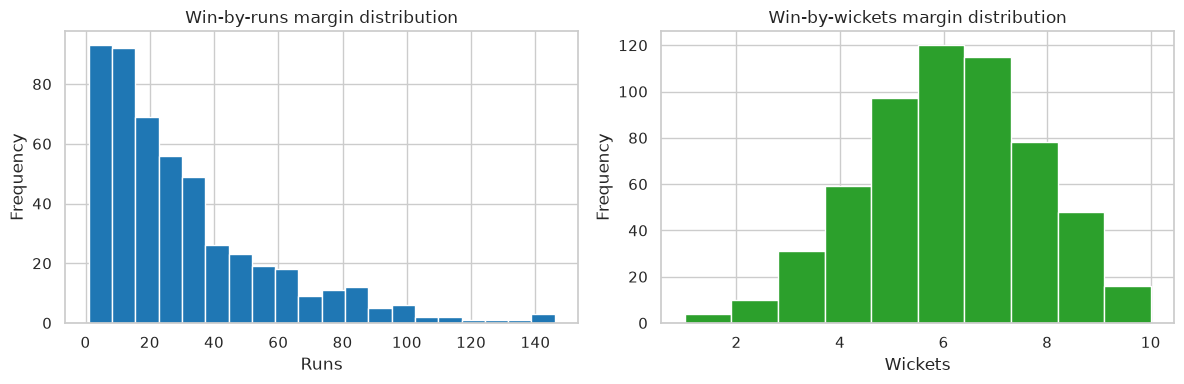

In [7]:
runs_wins = decided[decided["result"] == "runs"]
wkts_wins = decided[decided["result"] == "wickets"]
print(f"Wins batting first (by runs): {len(runs_wins)} | median margin "
      f"{runs_wins['result_margin'].median():.0f} runs, mean {runs_wins['result_margin'].mean():.1f}")
print(f"Wins chasing (by wickets): {len(wkts_wins)} | median margin "
      f"{wkts_wins['result_margin'].median():.0f} wickets")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
runs_wins["result_margin"].plot(kind="hist", bins=20, ax=axes[0], color="#1f77b4")
axes[0].set_title("Win-by-runs margin distribution"); axes[0].set_xlabel("Runs")
wkts_wins["result_margin"].plot(kind="hist", bins=10, ax=axes[1], color="#2ca02c")
axes[1].set_title("Win-by-wickets margin distribution"); axes[1].set_xlabel("Wickets")
plt.tight_layout(); plt.show()

## 8. Team performance over the seasons

Season-by-season wins for the five most successful teams — dynasties and declines at a glance.

winner  Mumbai Indians  Chennai Super Kings  Kolkata Knight Riders  Royal Challengers Bengaluru  Delhi Capitals
season                                                                                                         
2008                 7                    9                      6                            4               7
2009                 5                    8                      3                            9              10
2010                11                    9                      7                            8               7
2011                10                   11                      8                           10               4
2012                10                   10                     12                            8              11
2013                13                   12                      6                            9               3
2014                 7                   10                     11                            5         

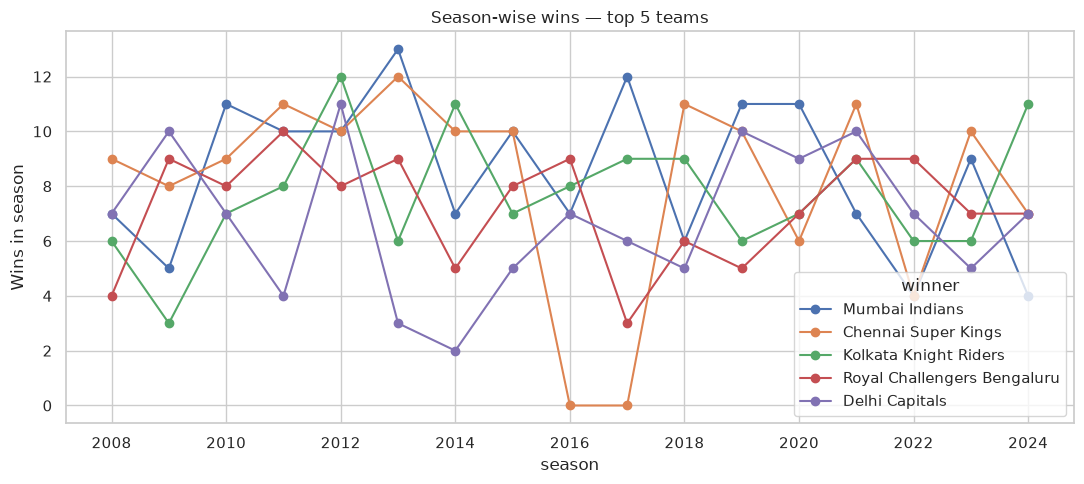

In [8]:
top5_teams = wins.head(5).index.tolist()
season_wins = (decided[decided["winner"].isin(top5_teams)]
               .groupby(["season", "winner"]).size().unstack(fill_value=0)
               .reindex(columns=top5_teams))
print(season_wins.to_string())

ax = season_wins.plot(kind="line", marker="o", figsize=(11, 5))
ax.set_ylabel("Wins in season"); ax.set_title("Season-wise wins — top 5 teams")
plt.tight_layout(); plt.show()

## 9. Batting records (ball-by-ball)

Career runs and strike rates from deliveries.csv, innings 1 & 2 only (super overs excluded). Strike-rate table needs a minimum of 500 balls faced so part-time batters don't distort it.

Top 10 run scorers (all seasons):
                runs  balls  innings  strike_rate
batter                                           
V Kohli         8004   6232      244       128.43
S Dhawan        6769   5481      221       123.50
RG Sharma       6628   5180      251       127.95
DA Warner       6565   4844      184       135.53
SK Raina        5528   4174      200       132.44
MS Dhoni        5243   3947      228       132.84
AB de Villiers  5162   3479      170       148.38
CH Gayle        4965   3502      141       141.78
RV Uthappa      4952   3925      197       126.17
KD Karthik      4842   3684      233       131.43

Highest strike rates (min 500 balls faced):
                 runs  balls  innings  strike_rate
batter                                            
AD Russell       2484   1512      104       164.29
H Klaasen         993    613       32       161.99
SP Narine        1534    984      106       155.89
N Pooran         1769   1141       72       155.04
LS Livingstone 

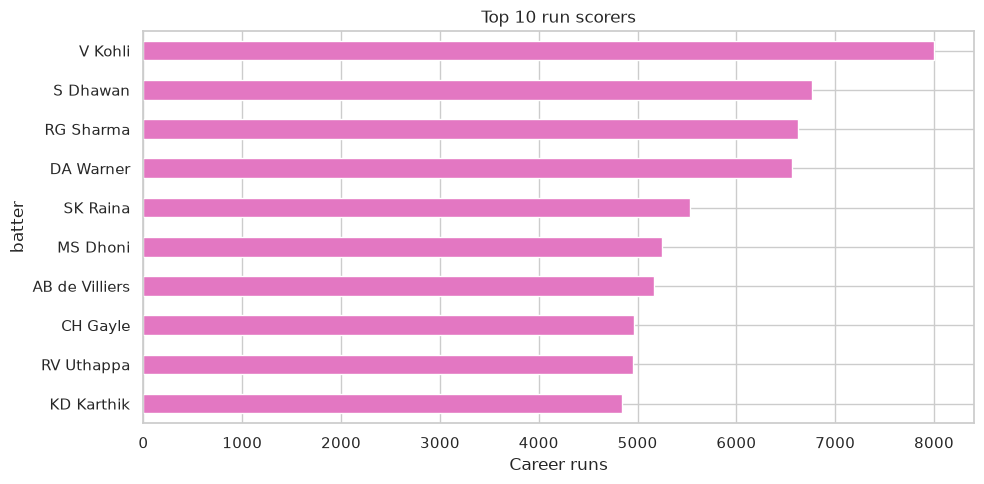

In [9]:
bat = d12.groupby("batter").agg(runs=("batsman_runs", "sum"),
                                balls=("ball", "count"),
                                innings=("match_id", "nunique"))
bat["strike_rate"] = (100 * bat["runs"] / bat["balls"]).round(2)
top_scorers = bat.sort_values("runs", ascending=False).head(10)
print("Top 10 run scorers (all seasons):"); print(top_scorers.to_string())

qualified = bat[bat["balls"] >= 500].sort_values("strike_rate", ascending=False)
print("\nHighest strike rates (min 500 balls faced):")
print(qualified.head(10).to_string())

ax = top_scorers["runs"].sort_values().plot(kind="barh", color="#e377c2")
ax.set_xlabel("Career runs"); ax.set_title("Top 10 run scorers")
plt.tight_layout(); plt.show()

## 10. Bowling records (ball-by-ball)

Wickets credited to bowlers — run outs are excluded because they are not the bowler's wicket. Wides don't count as balls bowled.

Top 10 wicket takers (run outs excluded — not credited to the bowler):
            wickets  balls  overs
bowler                           
YS Chahal       205   3530  588.2
PP Chawla       192   3852  642.0
DJ Bravo        183   3129  521.3
B Kumar         181   3922  653.4
R Ashwin        181   4528  754.4
SP Narine       180   4079  679.5
A Mishra        174   3392  565.2
SL Malinga      170   2846  474.2
JJ Bumrah       165   3085  514.1
RA Jadeja       160   3834  639.0


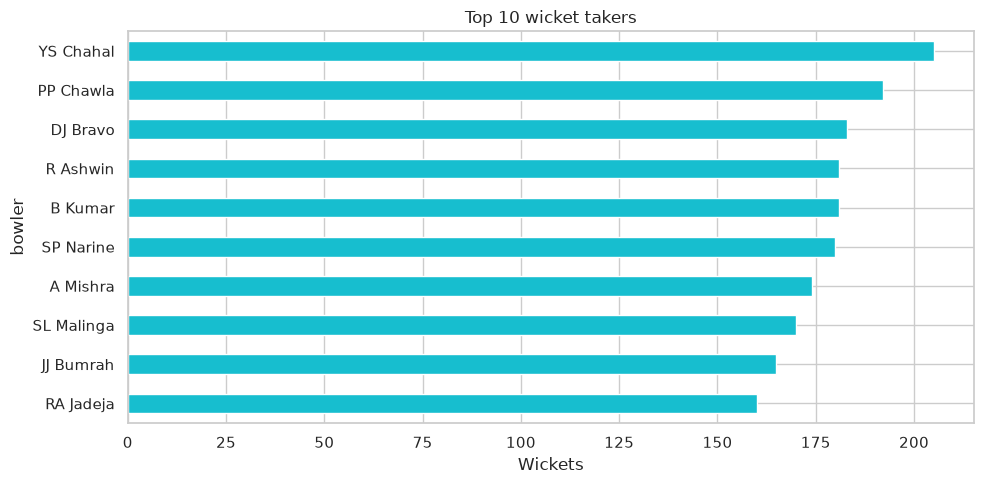

In [10]:
legal = d12[d12["extras_type"] != "wides"]  # wides do not count as balls bowled
player_wkts = d12[d12["is_wicket"] == 1]
bowler_wkts = player_wkts[player_wkts["dismissal_kind"] != "run out"]
top_bowlers = bowler_wkts.groupby("bowler").size().sort_values(ascending=False).head(10)
balls_bowled = legal.groupby("bowler").size()
bowler_table = pd.DataFrame({"wickets": top_bowlers,
                             "balls": balls_bowled.loc[top_bowlers.index]})
bowler_table["overs"] = (bowler_table["balls"] // 6).astype(str) + "." + (bowler_table["balls"] % 6).astype(str)
print("Top 10 wicket takers (run outs excluded — not credited to the bowler):")
print(bowler_table.to_string())

ax = top_bowlers.sort_values().plot(kind="barh", color="#17becf")
ax.set_xlabel("Wickets"); ax.set_title("Top 10 wicket takers")
plt.tight_layout(); plt.show()

## 11. Orange Cap & Purple Cap races — last 3 seasons

Top 5 run scorers and wicket takers for each of the three most recent seasons in the data.

In [11]:
season_of = matches.set_index("id")["season"]
d12s = d12.copy(); d12s["season"] = d12s["match_id"].map(season_of)
recent = sorted(d12s["season"].dropna().unique())[-3:]

orange, purple = {}, {}
for s in recent:
    sd = d12s[d12s["season"] == s]
    orange[s] = sd.groupby("batter")["batsman_runs"].sum().sort_values(ascending=False).head(5)
    sd_w = sd[(sd["is_wicket"] == 1) & (sd["dismissal_kind"] != "run out")]
    purple[s] = sd_w.groupby("bowler").size().sort_values(ascending=False).head(5)

for s in recent:
    print(f"\n=== {s} Orange Cap race (top 5) ==="); print(orange[s].to_string())
    print(f"\n=== {s} Purple Cap race (top 5) ==="); print(purple[s].to_string())


=== 2022 Orange Cap race (top 5) ===
batter
JC Buttler      863
KL Rahul        616
Q de Kock       508
HH Pandya       487
Shubman Gill    483

=== 2022 Purple Cap race (top 5) ===
bowler
YS Chahal        27
PWH de Silva     26
K Rabada         23
Umran Malik      22
Kuldeep Yadav    21

=== 2023 Orange Cap race (top 5) ===
batter
Shubman Gill    890
F du Plessis    730
DP Conway       672
V Kohli         639
YBK Jaiswal     625

=== 2023 Purple Cap race (top 5) ===
bowler
Mohammed Shami    28
MM Sharma         27
Rashid Khan       27
PP Chawla         22
TU Deshpande      21

=== 2024 Orange Cap race (top 5) ===
batter
V Kohli       741
RD Gaikwad    583
R Parag       573
TM Head       567
SV Samson     531

=== 2024 Purple Cap race (top 5) ===
bowler
HV Patel        24
CV Varun        21
Avesh Khan      20
JJ Bumrah       20
Harshit Rana    19


## 12. Key numbers — summary

In [12]:
decided_n = len(decided)
print("KEY NUMBERS")
print(f"Seasons covered: {matches['season'].nunique()} ({matches['season'].min()}–{matches['season'].max()})")
print(f"Total matches: {len(matches)} (decided: {decided_n}, no result: {len(matches) - decided_n})")
print(f"Ball-by-ball deliveries analysed: {len(d12)} (innings 1 & 2)")
print(f"Most wins: {wins.index[0]} — {wins.iloc[0]}")
print(f"Toss edge: toss winner won {toss_win_pct:.1f}% of decided matches")
print(f"Top run scorer: {top_scorers.index[0]} — {top_scorers['runs'].iloc[0]} runs")
print(f"Top wicket taker: {top_bowlers.index[0]} — {top_bowlers.iloc[0]} wickets")
print(f"Most POM awards: {pom.index[0]} — {pom.iloc[0]}")

KEY NUMBERS
Seasons covered: 17 (2008–2024)
Total matches: 1095 (decided: 1090, no result: 5)
Ball-by-ball deliveries analysed: 260759 (innings 1 & 2)
Most wins: Mumbai Indians — 144
Toss edge: toss winner won 50.8% of decided matches
Top run scorer: V Kohli — 8004 runs
Top wicket taker: YS Chahal — 205 wickets
Most POM awards: AB de Villiers — 25
